In [7]:
import os
import bisect
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from pathlib2 import Path
from wavelet_analysis import morlet_mean_power

### Инициализация путей

In [8]:
work_dir = Path(r"C:\Users\alvar\Documents\practice\test_repo_spectral_analysis")
path_to_data = work_dir / "sum_edges_triples"
path_to_data.mkdir(exist_ok=True, parents=True)
path_to_save_figure = work_dir / "figures" / "spectra"
path_to_save_figure.mkdir(exist_ok=True, parents=True)

### Определение параметров

In [9]:
mouse_data = path_to_data / "CA1_22_1D.npz"
llm_data = path_to_data / "sum_edges_triples_synthetic_data.npz"
null_data = "null_model_edges.npz"   # кэш нуль-модели; если файла нет, она считается заново

fs = 20.0                            # частота кадров, Гц
freqs = np.logspace(-1, 1, 120)      # 0,1–10 Гц, логарифмическая сетка
n_cells, T, W, p_spike, seed = 562, 18775, 40, 0.0008, 0   # параметры нуль-модели
out_figure = path_to_save_figure / "number_of_edges_spectra.pdf"
# ---------------------------------------------------------------------

CM = 1 / 2.54
plt.rcParams.update({"font.size": 8, 
                     "axes.titlesize": 8, 
                     "axes.labelsize": 8, 
                     "legend.fontsize": 7.5,
                     "xtick.labelsize": 8, 
                     "ytick.labelsize": 8, 
                     "pdf.fonttype": 42,
                     "axes.spines.top": False, 
                     "axes.spines.right": False})
C_M, C_L, C_N = "#1f5fa8", "#d9711a", "#666666"

### Функции для расчета спектра числа рёбер и генерации пуассоновской нуль-модели

In [10]:

def poisson_edges():
    """Ряд числа рёбер для независимых пуассоновских спайков (правило окна W кадров)."""
    rng = np.random.default_rng(seed)
    S = rng.random((T, n_cells)) < p_spike
    times = [np.where(S[:, n])[0] for n in range(n_cells)]
    cnt = np.zeros(T + 1)
    for t, i in sorted((t, n) for n in range(n_cells) for t in times[n]):
        for j in range(n_cells):
            if j == i:
                continue
            tj = times[j]
            k = bisect.bisect_right(tj, t)
            if k < len(tj) and tj[k] <= t + W:
                cnt[t:tj[k]] += 1
    return cnt[:T]


def local_beta(freqs, power, win=0.3):
    """beta(f) = -d log P / d log f в скользящем окне win декад (сетка частот логарифмическая)."""
    lf, lp = np.log10(freqs), np.log10(power)
    beta = np.full(len(lf), np.nan)
    for k, c in enumerate(lf):
        if c - win / 2 < lf[0] or c + win / 2 > lf[-1]:
            continue
        m = np.abs(lf - c) <= win / 2
        beta[k] = -np.polyfit(lf[m], lp[m], 1)[0]
    return beta




In [11]:
spectra = {}
for key, path in [("mouse", mouse_data), ("llm", llm_data)]:
    with np.load(path) as z:
        spectra[key] = morlet_mean_power(z["sum_edges"], frequencies=freqs, fs=fs, w=6.0)

if os.path.exists(null_data):
    with np.load(null_data) as z:
        null_freqs, null_power = z["freqs"], z["var"]          # формат null_model_edges.py
    null_power = np.interp(np.log10(freqs), np.log10(null_freqs), null_power)
else:
    print("Расчет пуассоновской нуль-модели")
    null_power = morlet_mean_power(poisson_edges(), frequencies=freqs, fs=fs, w=6.0)
    np.savez(null_data, freqs=freqs, var=null_power)
spectra["null"] = null_power


### Отрисовка графиков

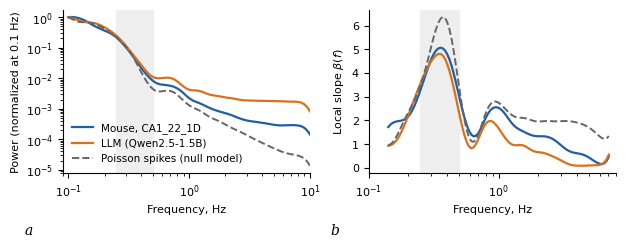

: 

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16 * CM, 6.2 * CM))
styles = [("mouse", C_M, "-", "Mouse, CA1_22_1D"),
          ("llm", C_L, "-", "LLM (Qwen2.5-1.5B)"),
          ("null", C_N, "--", "Poisson spikes (null model)")]
for key, col, ls, lab in styles:
    p = spectra[key]
    ax[0].plot(freqs, p / p[0], color=col, ls=ls, lw=1.6 if ls == "-" else 1.4, label=lab)  # нормировка на 0,1 Гц
    ax[1].plot(freqs, local_beta(freqs, p), color=col, ls=ls, lw=1.6 if ls == "-" else 1.4)

for a in ax:
    a.axvspan(0.25, 0.5, color="#eeeeee", zorder=0)
    a.set_xscale("log"); a.set_xlabel("Frequency, Hz")
    a.xaxis.set_minor_formatter(mt.NullFormatter())
ax[0].set_yscale("log"); ax[0].set_xlim(0.09, 10)
ax[0].set_ylabel("Power (normalized at 0.1 Hz)"); ax[0].legend(frameon=False, loc="lower left")
ax[1].set_xlim(0.1, 8); ax[1].set_ylabel(r"Local slope $\beta(f)$")

plt.tight_layout(rect=(0, 0.06, 1, 1))

for a, letter in zip(ax, "ab"):                     # буквы a, b в левом нижнем углу
    fig.text(a.get_position().x0 - 0.06, 0.015, letter, fontsize=10, style="italic",
             family="serif", ha="left", va="bottom")

if out_figure is not None:
    fig.savefig(out_figure)
    fig.savefig(str(out_figure).rsplit(".", 1)[0] + ".png", dpi=300)
plt.show()